# Lab 17.3: Superposition and Dictionaries You Can Check

Chapter 17, Features, Superposition and Sparse Autoencoders. Run the cells from top to bottom. Two cells are marked **EDIT** if you want to experiment; everything else only needs to be run.

Every model here is tiny and synthetic, so the *true* features are known. That is the point: on a real language model nobody knows the true features, so we practice the measurements where they can be checked.

In [1]:
import numpy as np, torch, matplotlib.pyplot as plt, time
torch.set_num_threads(2)
T0 = time.time()

def sparse_batch(gen, B, n, density):
    """Each feature is 0 with probability 1 - density, otherwise uniform on [0, 1]."""
    x = torch.rand(B, n, generator=gen)
    return x * (torch.rand(B, n, generator=gen) < density)

def train_toy(n, m, density, importance, seed=0, steps=5000):
    """Toy model of superposition (Elhage et al., 2022): h = W x, x_hat = ReLU(W^T h + b)."""
    gen = torch.Generator().manual_seed(seed)
    W = (torch.randn(m, n, generator=gen) * 0.3).requires_grad_()
    b = torch.zeros(n, requires_grad=True)
    opt = torch.optim.Adam([W, b], lr=3e-3)
    I = torch.tensor(importance, dtype=torch.float32)
    for _ in range(steps):
        x = sparse_batch(gen, 1024, n, density)
        x_hat = torch.relu((x @ W.T) @ W + b)
        loss = (I * (x - x_hat) ** 2).sum(1).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    return W.detach().numpy(), b.detach().numpy(), float(loss)

## Part A. How many features fit in two neurons?

Five features with importance 0.8^i are squeezed into two neurons. We vary only the density (the share of inputs in which each feature is active) and count the features the model stores (a column of W with length above 0.5). For each density we keep the best of three random starts.

In [2]:
n, m = 5, 2
imp = [0.8 ** i for i in range(n)]
densities = [1.0, 0.5, 0.25, 0.1, 0.05, 0.02]
toy = {}
print("density  stored  column lengths")
for d in densities:
    W, b, loss = min((train_toy(n, m, d, imp, seed=s) for s in range(3)), key=lambda r: r[2])
    toy[d] = (W, b)
    norms = np.linalg.norm(W, axis=0)
    print(f"{d:7.2f}  {int((norms > 0.5).sum()):6d}  {np.round(norms, 2)}")

density  stored  column lengths


   1.00       2  [1. 1. 0. 0. 0.]


   0.50       4  [1.02 1.01 0.86 0.87 0.01]


   0.25       4  [1.02 1.02 1.   0.99 0.  ]


   0.10       4  [1.01 1.01 1.01 1.   0.01]


   0.05       5  [1.14 1.13 1.14 1.11 1.09]


   0.02       5  [1.16 1.16 1.16 1.15 1.12]


**Checkpoint 1.** With dense features (density 1.0) the model stores 2 features, the two most important; as density falls it stores 4 and then all 5. The exact density at which the switch happens can move a little with the random seed.

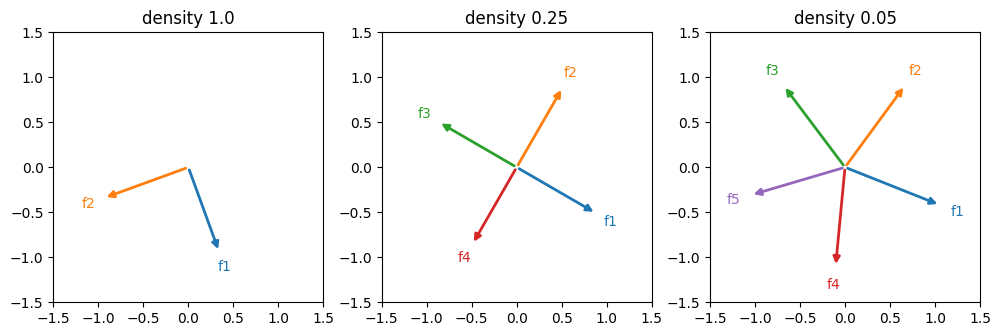

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
for ax, d in zip(axes, [1.0, 0.25, 0.05]):
    W = toy[d][0]
    for i in range(n):
        if np.linalg.norm(W[:, i]) > 0.15:
            ax.annotate("", xy=W[:, i], xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", lw=2, color=f"C{i}"))
            ax.text(*(W[:, i] * 1.18), f"f{i+1}", color=f"C{i}", ha="center", va="center")
    ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.5, 1.5); ax.set_aspect("equal"); ax.set_title(f"density {d}")
plt.tight_layout(); plt.show()

### Interference

In the sparsest model all five features share two dimensions. What happens when two features are active *at the same time*, which sparsity makes rare? Below, feature 1 alone, then feature 1 together with each other feature.

In [4]:
W, b = toy[0.05]
def rebuild(x):
    return np.maximum(W.T @ (W @ x) + b, 0)
x = np.zeros(5); x[0] = 1.0
print("f1 alone      ->", np.round(rebuild(x), 2))
for j in range(1, 5):
    x = np.zeros(5); x[0] = 1.0; x[j] = 1.0
    print(f"f1 and f{j+1} on ->", np.round(rebuild(x), 2))
print("cosine between stored directions:")
U = W / np.linalg.norm(W, axis=0, keepdims=True)
print(np.round(U.T @ U, 2))

f1 alone      -> [1.06 0.1  0.   0.13 0.  ]
f1 and f2 on -> [1.38 1.38 0.   0.   0.  ]
f1 and f3 on -> [0.   0.47 0.   0.   0.  ]
f1 and f4 on -> [1.42 0.   0.   1.36 0.  ]
f1 and f5 on -> [0.09 0.   0.   0.58 0.  ]
cosine between stored directions:
[[ 1.    0.25 -0.85  0.28 -0.79]
 [ 0.25  1.    0.29 -0.86 -0.8 ]
 [-0.85  0.29  1.   -0.74  0.35]
 [ 0.28 -0.86 -0.74  1.    0.37]
 [-0.79 -0.8   0.35  0.37  1.  ]]


**Checkpoint 2.** Alone, feature 1 is rebuilt well and the others stay near zero (the negative biases filter small interference). With two features on, the rebuilt values are distorted: features whose directions overlap positively leak into each other, and features in opposite directions cancel. This is the price of superposition, paid only in rare inputs.

## Part B. Polysemantic neurons, and a dictionary that separates them

Now a slightly bigger toy with a ReLU on its neurons, so that neurons are a special basis: 24 sparse features through 8 neurons. Then we train a sparse autoencoder (SAE) with 48 latents on the neurons' activations and compare how many features each neuron and each latent responds to.

In [5]:
def train_sae(X, k, l1, seed=0, steps=3000, lr=3e-3, batch=1024):
    """ReLU SAE: f = ReLU(W_e (x - b_d) + b_e), x_hat = W_d f + b_d, unit-norm decoder columns."""
    gen = torch.Generator().manual_seed(seed)
    N, d = X.shape
    Wd = torch.randn(d, k, generator=gen); Wd = (Wd / Wd.norm(dim=0, keepdim=True)).requires_grad_()
    We = Wd.detach().T.clone().requires_grad_()
    be = torch.zeros(k, requires_grad=True); bd = torch.zeros(d, requires_grad=True)
    opt = torch.optim.Adam([We, Wd, be, bd], lr=lr)
    for _ in range(steps):
        xb = X[torch.randint(0, N, (batch,), generator=gen)]
        f = torch.relu((xb - bd) @ We.T + be)
        loss = ((xb - (f @ Wd.T + bd)) ** 2).sum(1).mean() + l1 * f.sum(1).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():
            Wd /= Wd.norm(dim=0, keepdim=True)
    with torch.no_grad():
        f = torch.relu((X - bd) @ We.T + be); xh = f @ Wd.T + bd
        fvu = float(((X - xh) ** 2).sum() / ((X - X.mean(0)) ** 2).sum())
        l0 = float((f > 0).float().sum(1).mean())
    encode = lambda Z: torch.relu((Z - bd) @ We.T + be).detach()
    return Wd.detach().numpy(), encode, fvu, l0

n2, m2 = 24, 8
gen = torch.Generator().manual_seed(3)
W1 = (torch.randn(m2, n2, generator=gen) * 0.3).requires_grad_(); b1 = torch.zeros(m2, requires_grad=True)
W2 = (torch.randn(n2, m2, generator=gen) * 0.3).requires_grad_(); b2 = torch.zeros(n2, requires_grad=True)
opt = torch.optim.Adam([W1, b1, W2, b2], lr=3e-3)
for _ in range(6000):
    x = sparse_batch(gen, 1024, n2, 0.04)
    h = torch.relu(x @ W1.T + b1)
    loss = ((x - torch.relu(h @ W2.T + b2)) ** 2).sum(1).mean()
    opt.zero_grad(); loss.backward(); opt.step()
neurons = lambda x: torch.relu(x @ W1.T + b1).detach()
H = neurons(sparse_batch(gen, 40000, n2, 0.04))
Wd, encode, fvu, l0 = train_sae(H, 48, 0.15, seed=1, steps=3000)
print(f"toy model loss {float(loss):.3f}; SAE on neurons: unexplained variance {fvu:.3f}, L0 {l0:.2f}")

toy model loss 0.090; SAE on neurons: unexplained variance 0.029, L0 1.92


features per neuron: [3 5 4 4 5 6 3 1]  mean 3.88
features per latent: [1 1 2 1 3 1 1 1 2 5 2 1 1 1 1 1]  mean 1.56


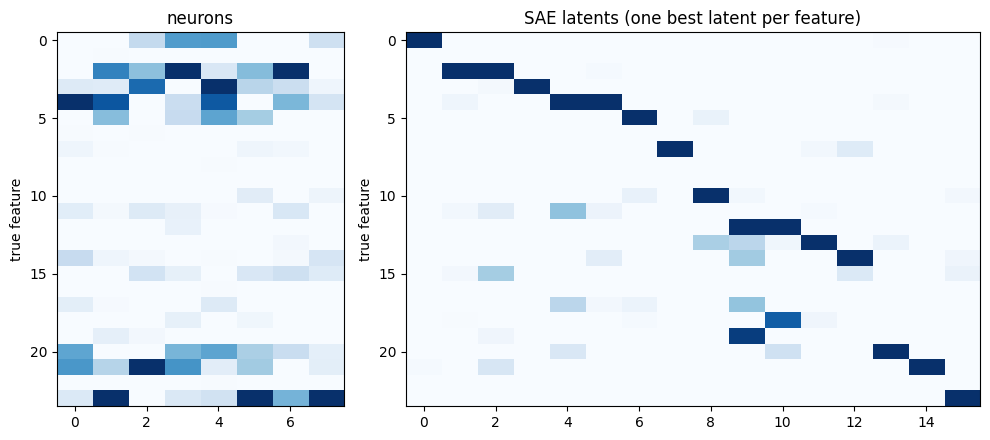

In [6]:
E = torch.eye(n2)                          # switch on one true feature at a time
Z = torch.zeros(1, n2)                     # the empty input, subtracted as a baseline
Rn = np.maximum(neurons(E).numpy() - neurons(Z).numpy(), 0)                  # 24 features x 8 neurons
Rs = np.maximum(encode(neurons(E)).numpy() - encode(neurons(Z)).numpy(), 0)  # 24 features x 48 latents
used = sorted(set(int(np.argmax(Rs[i])) for i in range(n2) if Rs[i].max() > 1e-3), key=lambda j: int(np.argmax(Rs[:, j])))
scale = lambda R: R / (R.max(0, keepdims=True) + 1e-9)
per_neuron = (scale(Rn) > 0.25).sum(0)
per_latent = (scale(Rs[:, used]) > 0.25).sum(0)
print("features per neuron:", per_neuron, " mean", per_neuron.mean().round(2))
print("features per latent:", per_latent, " mean", per_latent.mean().round(2))
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), gridspec_kw=dict(width_ratios=[8, len(used)]))
axes[0].imshow(scale(Rn), cmap="Blues", aspect="auto"); axes[0].set_title("neurons")
axes[1].imshow(scale(Rs[:, used]), cmap="Blues", aspect="auto"); axes[1].set_title("SAE latents (one best latent per feature)")
for ax in axes: ax.set_ylabel("true feature")
plt.tight_layout(); plt.show()

**Checkpoint 3.** Each neuron responds to several true features (mean about 4); each latent the SAE uses responds to one or two (mean about 1.5). Some rows are blank in both maps: features the toy network did not store. One or two features may be split across two latents or share one: the SAE is good, not perfect, even here.

## Part C. Does better reconstruction mean better features?

Synthetic activations: 96 true feature directions in 32 dimensions, each feature active in 2 percent of samples (about 1.9 active per sample). We train SAEs with three dictionary sizes and several sparsity penalties, and measure sparsity (L0), unexplained variance, and the share of true features recovered (some decoder direction with cosine above 0.9).

In [7]:
# EDIT: try other penalties or dictionary sizes here
L1_VALUES = [0.05, 0.2, 0.5, 1.0, 2.0, 4.0]
DICT_SIZES = [48, 96, 192]

rng = np.random.default_rng(11)
d, n3, N, p = 32, 96, 16000, 0.02
D = rng.normal(size=(n3, d)); D /= np.linalg.norm(D, axis=1, keepdims=True)
C = rng.exponential(size=(N, n3)) * (rng.random((N, n3)) < p)
X = torch.tensor(C @ D, dtype=torch.float32)
print("true mean active features per sample:", (C > 0).sum(1).mean().round(2))
rows = []
for k in DICT_SIZES:
    for l1 in L1_VALUES:
        Wd3, _, fvu3, l03 = train_sae(X, k, l1, seed=2, steps=2000)
        rec = float((np.abs(D @ Wd3).max(1) > 0.9).mean())
        rows.append((k, l1, l03, fvu3, rec))
        print(f"latents {k:4d}  L1 {l1:6.3f}  L0 {l03:6.2f}  unexplained {fvu3:.3f}  recovered {rec:.2f}")

true mean active features per sample: 1.9


latents   48  L1  0.050  L0  18.57  unexplained 0.023  recovered 0.00


latents   48  L1  0.200  L0   9.65  unexplained 0.075  recovered 0.01


latents   48  L1  0.500  L0   4.29  unexplained 0.183  recovered 0.20


latents   48  L1  1.000  L0   1.89  unexplained 0.327  recovered 0.29


latents   48  L1  2.000  L0   0.88  unexplained 0.534  recovered 0.42


... (9 outputs left out)

latents  192  L1  0.500  L0   5.60  unexplained 0.118  recovered 0.88


latents  192  L1  1.000  L0   3.03  unexplained 0.187  recovered 0.98


latents  192  L1  2.000  L0   1.78  unexplained 0.353  recovered 0.97


latents  192  L1  4.000  L0   0.68  unexplained 0.793  recovered 0.59


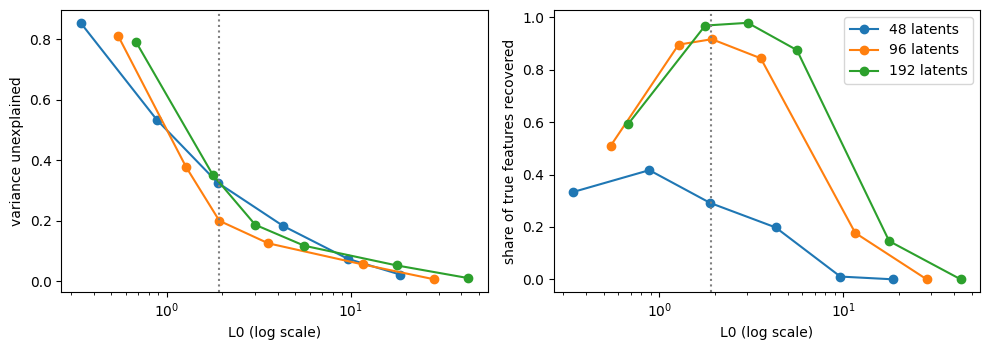

total run time 177 s


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for k in DICT_SIZES:
    rr = [r for r in rows if r[0] == k]
    axes[0].plot([r[2] for r in rr], [r[3] for r in rr], "o-", label=f"{k} latents")
    axes[1].plot([r[2] for r in rr], [r[4] for r in rr], "o-", label=f"{k} latents")
for ax in axes:
    ax.set_xscale("log"); ax.axvline(n3 * p, ls=":", color="gray"); ax.set_xlabel("L0 (log scale)")
axes[0].set_ylabel("variance unexplained"); axes[1].set_ylabel("share of true features recovered")
axes[1].legend(); plt.tight_layout(); plt.show()
print(f"total run time {time.time() - T0:.0f} s")

**Checkpoint 4.** Unexplained variance falls steadily as L0 rises. Recovery is near zero for dense dictionaries (L0 above about 10), reaches about 0.85 to 1.0 for the 96- and 192-latent dictionaries near the dotted line (the true number of active features, about 1.9), and drops again when fewer than one latent is active; the 48-latent dictionary never passes about 0.4. A team that tuned only for reconstruction would pick a dictionary that recovers fewer real features (compare the chapter's Figure "tradeoff" and the critique by Korznikov et al., 2026).

## Questions

1. In Part A, which features were dropped first as density rose, and why those?
2. In Part B, pick one neuron and list the features it responds to. Would a label written from its top activations be faithful?
3. In Part C, you must choose a dictionary for a real model where recovery cannot be measured. Which measurements would you use instead, and what would you still be unable to tell?